# Prior and posterior checks for the coupling model

This notebook is organized exactly as the preregistration checks: **A. prior checks**, **B. computational checks on simulated data**, and **C. posterior checks**.  The default settings below are intentionally small so the notebook can be executed as a pipeline smoke test.  For preregistration-grade checks, increase `N_PRIOR_DRAWS`, `N_PRIOR_PREDICTIVE`, `SBC_REPLICATES`, posterior draws, and the number of model-recovery repetitions.

The notebook uses the live implementation in `coupling_sources.core.model` and the direct simulator in `coupling_sources.core.simulator`; it does not use an adapter layer.  Metadata created by the simulator is passed as unused keyword arguments when needed.

In [1]:
from __future__ import annotations

from pathlib import Path
from math import ceil
import warnings

import arviz as az
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import pandas as pd
from numpyro.handlers import condition
from scipy.special import logsumexp
from scipy.stats import vonmises

from coupling_sources.checks import (
    DEG,
    TWO_PI,
    benchmark_designated_weight,
    correction_index_values,
    dataset_indices,
    angular_error_values,
    flatten_valid,
    kappa_for_approx_sd_deg,
    make_locked_design,
    parameter_transforms,
    partner_proximity_values,
    posterior_draw_dict,
    posterior_predictive,
    probe_freezing_delta,
    response_log_likelihood_by_trial,
    score_contrast,
    simulate_design,
    states_for_params,
    wrap_pi,
)
from coupling_sources.core.constants import HIDDEN_SOURCE_PROBE
from coupling_sources.core.data import SimulationBatch
from coupling_sources.core.model import model_coupling
from coupling_sources.core.priors import coupling_parameter_sites, sample_coupling_parameter_draws
numpyro.set_host_device_count(1)
warnings.filterwarnings("ignore", category=UserWarning)

ARTIFACT_DIR = Path("artifacts/checks")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

SMOKE = True
N_PRIOR_DRAWS = 1_000 if SMOKE else 50_000
N_TRAJECTORY_DRAWS = 40 if SMOKE else 400
N_PRIOR_PREDICTIVE = 30 if SMOKE else 2_000
SBC_REPLICATES = 1 if SMOKE else 300
SBC_POSTERIOR_DRAWS = 10 if SMOKE else 100
MCMC_WARMUP = 5 if SMOKE else 600
MCMC_SAMPLES = 15 if SMOKE else 1_000
POSTERIOR_PPC_DRAWS = 15 if SMOKE else 400

RUN_FITS_IN_NOTEBOOK = False  # precomputed smoke fits keep execution fast; set True to recompute MCMC in-place
PRECOMPUTED_FIT_RESULTS = ARTIFACT_DIR / "smoke_fit_results.json"
PRECOMPUTED_FIT_SAMPLES = ARTIFACT_DIR / "smoke_fit_samples.npz"
PARAMETER_SITES = coupling_parameter_sites()

rng = np.random.default_rng(20260705)
print(f"NumPyro {numpyro.__version__}; smoke mode = {SMOKE}; run fits in notebook = {RUN_FITS_IN_NOTEBOOK}")

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


NumPyro 0.21.0; smoke mode = True; run fits in notebook = False


In [2]:
def savefig(fig, name: str) -> None:
    fig.savefig(ARTIFACT_DIR / name, dpi=160, bbox_inches="tight")


def flatten_parameter_samples(samples: dict[str, np.ndarray]) -> dict[str, np.ndarray]:
    return {name: np.asarray(samples[name]).reshape(-1) for name in PARAMETER_SITES if name in samples}


def fit_simulation(simulation: SimulationBatch, *, seed: int, warmup: int = MCMC_WARMUP, samples: int = MCMC_SAMPLES):
    kernel = numpyro.infer.NUTS(model_coupling, target_accept_prob=0.8, max_tree_depth=6 if SMOKE else 10)
    mcmc = numpyro.infer.MCMC(kernel, num_warmup=warmup, num_samples=samples, num_chains=1, progress_bar=False)
    mcmc.run(
        jax.random.PRNGKey(seed),
        simulation,
        extra_fields=("diverging",),
    )
    return mcmc


def sample_prior_params(seed: int, draws: int) -> dict[str, np.ndarray]:
    return {k: np.asarray(v) for k, v in sample_coupling_parameter_draws(seed=seed, draws=draws).items()}


def log_likelihood_matrix(samples: dict[str, np.ndarray], simulation: SimulationBatch, design, *, max_draws: int | None = None) -> np.ndarray:
    flat = flatten_parameter_samples(samples)
    n_draws = len(next(iter(flat.values())))
    draw_indices = np.arange(n_draws) if max_draws is None else np.linspace(0, n_draws - 1, min(max_draws, n_draws), dtype=int)
    valid = np.asarray(design.valid_trials).reshape(-1)
    rows = []
    for draw_index in draw_indices:
        params = {name: float(values[draw_index]) for name, values in flat.items()}
        rows.append(response_log_likelihood_by_trial(simulation, design, params).reshape(-1)[valid])
    return np.asarray(rows)


def elpd_i_from_loglik(loglik: np.ndarray) -> np.ndarray:
    return logsumexp(loglik, axis=0) - np.log(loglik.shape[0])


def transformed_frame(samples: dict[str, np.ndarray], label: str) -> pd.DataFrame:
    rows = []
    for name, values in parameter_transforms(samples).items():
        rows.extend({"scale": name, "value": float(x), "source": label} for x in np.asarray(values).reshape(-1))
    return pd.DataFrame(rows)


def natural_parameter_frame(samples: dict[str, np.ndarray], label: str) -> pd.DataFrame:
    rows = []
    for name in PARAMETER_SITES:
        rows.extend({"parameter": name, "value": float(x), "source": label} for x in np.asarray(samples[name]).reshape(-1))
    return pd.DataFrame(rows)

## A. Prior checks

The priors used by the model are on the intended transformed scales: `logit(alpha) ~ Normal(0, 1.5)`, `log(beta_y) ~ Normal(0, 1)`, `log(beta_z) ~ Normal(0, 1)`, and `log(kappa) ~ Normal(log(8), 1)`.  The figures below check the implied distributions on the natural scales used in behavioral reasoning.

In [3]:
prior = sample_prior_params(seed=1, draws=N_PRIOR_DRAWS)
prior_frame = natural_parameter_frame(prior, "prior")
prior_frame.groupby("parameter")["value"].quantile([0.05, 0.5, 0.95]).unstack()

,0.05,0.50,0.95
parameter,,,
alpha,0.076168,0.473607,0.914974
beta_y,0.191551,1.054491,5.524643
beta_z,0.205762,0.974924,4.900521
kappa,1.686457,7.820623,38.575966


### A1. Prior marginals on the natural scale

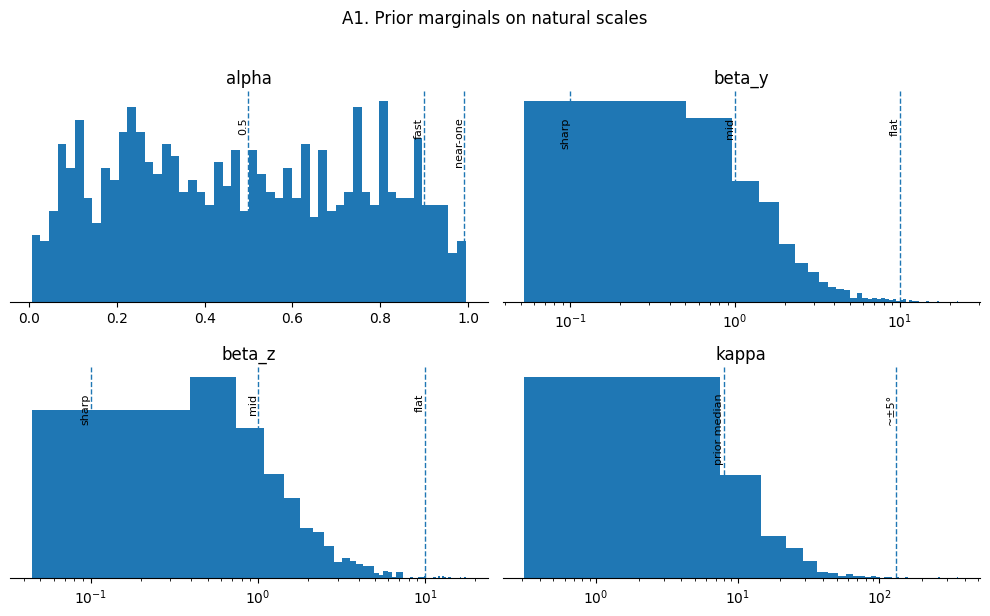

In [4]:
reference_lines = {
    "alpha": [(0.5, "0.5"), (0.9, "fast"), (0.99, "near-one")],
    "beta_y": [(0.1, "sharp"), (1.0, "mid"), (10.0, "flat")],
    "beta_z": [(0.1, "sharp"), (1.0, "mid"), (10.0, "flat")],
    "kappa": [(8.0, "prior median"), (kappa_for_approx_sd_deg(5), "~±5°")],
}
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, parameter in zip(axes.ravel(), PARAMETER_SITES):
    values = prior_frame.loc[prior_frame.parameter == parameter, "value"].to_numpy()
    ax.hist(values, bins=50, density=True)
    for x, label in reference_lines[parameter]:
        ax.axvline(x, linestyle="--", linewidth=1)
        ax.text(x, ax.get_ylim()[1] * 0.88, label, rotation=90, va="top", ha="right", fontsize=8)
    if parameter.startswith("beta") or parameter == "kappa":
        ax.set_xscale("log")
    ax.set_title(parameter)
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
fig.suptitle("A1. Prior marginals on natural scales", y=1.02)
fig.tight_layout()
savefig(fig, "A1_prior_marginals.png")
plt.show()

### A2. Temperature-to-weight map

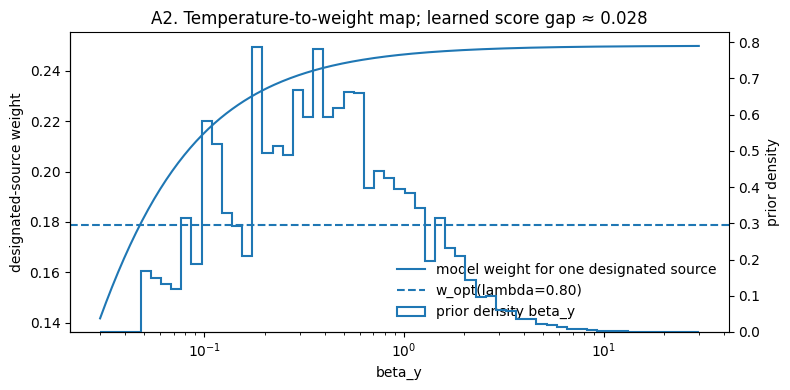

In [5]:
# Estimate the source-score contrast reached by the locked design using the model's actual learning rule.
contrast_design = make_locked_design(seed=12, n_participants=80, n_rounds=1, n_trials=18, probe_trials=(5, 11, 15), diagnostic_trials=(6, 12, 16), hidden_probe_source=(1, 2, 1))
asym_states = states_for_params(contrast_design, {"alpha": 0.95, "beta_y": 1.0, "beta_z": 1.0, "kappa": 8.0})
source_scores = np.asarray(asym_states.truth_source_scores)
truth_mask = np.asarray(contrast_design.trial_type) == 0
designated_score = source_scores[..., [0, 1]][truth_mask].mean()
other_score = source_scores[..., [2, 3]][truth_mask].mean()
score_gap = float(other_score - designated_score)

beta_grid = np.geomspace(0.03, 30.0, 300)
designated_weight = np.exp(designated_score / beta_grid) / (2 * np.exp(designated_score / beta_grid) + 2 * np.exp(other_score / beta_grid))
w_opt = benchmark_designated_weight(contrast_design.lam)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(beta_grid, designated_weight, label="model weight for one designated source")
ax.axhline(w_opt, linestyle="--", label=f"w_opt(lambda={contrast_design.lam:.2f})")
ax.set_xscale("log")
ax.set_xlabel("beta_y")
ax.set_ylabel("designated-source weight")
ax.set_title(f"A2. Temperature-to-weight map; learned score gap ≈ {score_gap:.3f}")
ax.spines[["top", "right"]].set_visible(False)
ax2 = ax.twinx()
ax2.hist(prior["beta_y"], bins=np.geomspace(0.03, 30.0, 60), density=True, histtype="step", linewidth=1.5, label="prior density beta_y")
ax2.set_xscale("log")
ax2.set_ylabel("prior density")
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, frameon=False, loc="best")
fig.tight_layout()
savefig(fig, "A2_temperature_weight_map.png")
plt.show()

### A3. Prior learning trajectories

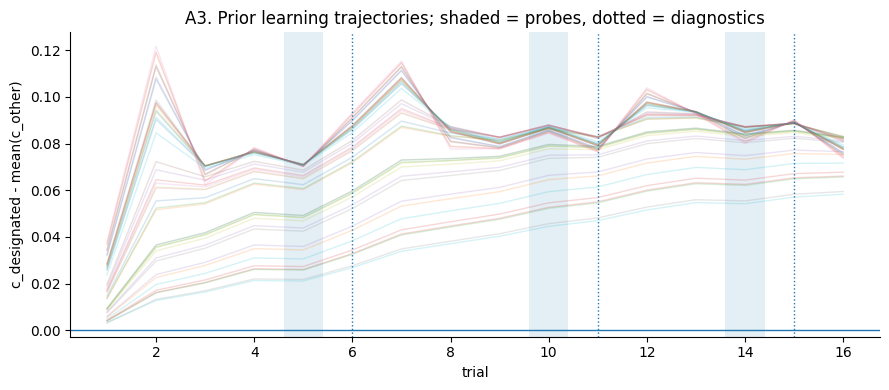

Max update on pairs involving the hidden source during probes: 0


In [6]:
trajectory_design = make_locked_design(seed=21, n_participants=20, n_rounds=1, n_trials=16, probe_trials=(4, 9, 13), diagnostic_trials=(5, 10, 14), hidden_probe_source=(1, 2, 1))
trajectory_prior = sample_prior_params(seed=22, draws=N_TRAJECTORY_DRAWS)
trial_axis = np.arange(1, trajectory_design.visible_reports.shape[2] + 1)
trajectories = []
freeze_checks = []
for draw_index in range(N_TRAJECTORY_DRAWS):
    params = {"alpha": trajectory_prior["alpha"][draw_index], "beta_y": 1.0, "beta_z": 1.0, "kappa": 8.0}
    states = states_for_params(trajectory_design, params)
    trajectories.append(score_contrast(states, trajectory_design.coupled_sources).mean(axis=(0, 1)))
    freeze_checks.append(probe_freezing_delta(states, trajectory_design.hidden_source))
trajectories = np.asarray(trajectories)

fig, ax = plt.subplots(figsize=(9, 4))
for y in trajectories:
    ax.plot(trial_axis, y, alpha=0.18, linewidth=1)
for t in trajectory_design.probe_trials:
    ax.axvspan(t + 0.6, t + 1.4, alpha=0.12)
for t in trajectory_design.diagnostic_trials:
    ax.axvline(t + 1, linestyle=":", linewidth=1)
ax.axhline(0, linewidth=1)
ax.set_xlabel("trial")
ax.set_ylabel("c_designated - mean(c_other)")
ax.set_title("A3. Prior learning trajectories; shaded = probes, dotted = diagnostics")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
savefig(fig, "A3_prior_learning_trajectories.png")
plt.show()
print(f"Max update on pairs involving the hidden source during probes: {np.max(freeze_checks):.3g}")

### A4. Prior predictive responses against the anchors

In [7]:
predictive_design = make_locked_design(seed=31, n_participants=8, n_rounds=2, n_trials=14, probe_trials=(3, 7, 11), diagnostic_trials=(4, 8, 12), hidden_probe_source=(1, 2, 1))
predictive_prior = sample_prior_params(seed=32, draws=N_PRIOR_PREDICTIVE)
indices = []
prior_error_rows = []
for draw_index in range(N_PRIOR_PREDICTIVE):
    sim = simulate_prior_dataset_seed = simulate_design(
        1000 + draw_index,
        predictive_design,
        dict(
            alpha=predictive_prior["alpha"][draw_index],
            beta_y=predictive_prior["beta_y"][draw_index],
            beta_z=predictive_prior["beta_z"][draw_index],
            kappa=predictive_prior["kappa"][draw_index],
        ),
    )
    item = dataset_indices(sim, predictive_design)
    item["draw"] = draw_index
    indices.append(item)
    errors = angular_error_values(sim, predictive_design)
    for kind, values in errors.items():
        for value in values:
            prior_error_rows.append({"draw": draw_index, "kind": kind, "error_deg": value / DEG})
index_frame = pd.DataFrame(indices)
index_frame.describe(percentiles=[0.05, 0.5, 0.95])

,CI,PP,draw
count,30.000000,30.000000,30.000000
mean,0.000067,0.055482,14.500000
std,1.137452,0.274069,8.803408
min,-1.746323,-0.377142,0.000000
5%,-1.424854,-0.360937,1.450000
50%,-0.165188,0.083202,14.500000
95%,2.456400,0.452228,27.550000
max,2.856750,0.675872,29.000000


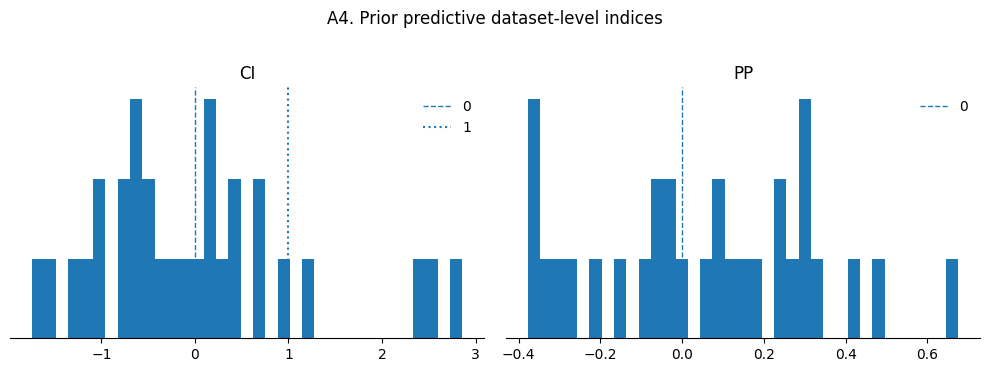

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, metric in zip(axes, ["CI", "PP"]):
    values = index_frame[metric].replace([np.inf, -np.inf], np.nan).dropna()
    ax.hist(values, bins=35, density=True)
    ax.axvline(0, linestyle="--", linewidth=1, label="0")
    if metric == "CI":
        ax.axvline(1, linestyle=":", linewidth=1.5, label="1")
    ax.set_title(metric)
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.legend(frameon=False)
fig.suptitle("A4. Prior predictive dataset-level indices", y=1.02)
fig.tight_layout()
savefig(fig, "A4_prior_predictive_indices.png")
plt.show()

### A5. Prior predictive angular error

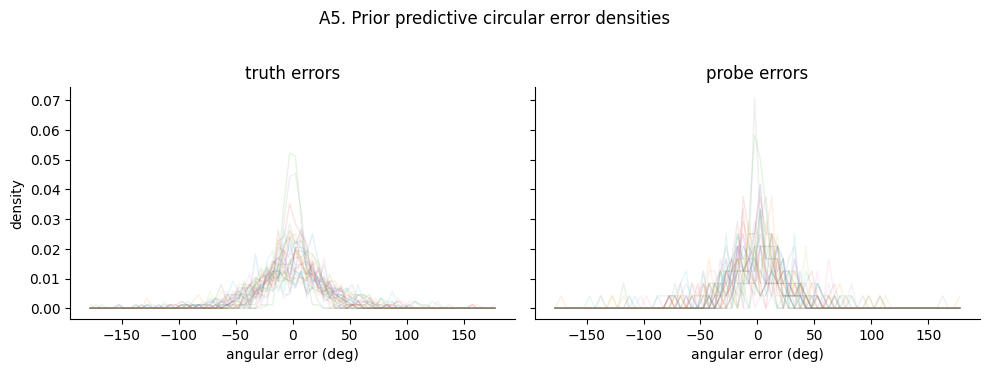

In [9]:
error_frame = pd.DataFrame(prior_error_rows)
bins = np.linspace(-180, 180, 73)
centers = 0.5 * (bins[:-1] + bins[1:])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, kind in zip(axes, ["truth", "probe"]):
    for draw, group in error_frame.loc[error_frame.kind == kind].groupby("draw"):
        hist, _ = np.histogram(group["error_deg"], bins=bins, density=True)
        ax.plot(centers, hist, alpha=0.12, linewidth=1)
    ax.set_title(f"{kind} errors")
    ax.set_xlabel("angular error (deg)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("density")
fig.suptitle("A5. Prior predictive circular error densities", y=1.02)
fig.tight_layout()
savefig(fig, "A5_prior_predictive_error_density.png")
plt.show()

## B. Computational checks on simulated data

The next cells deliberately use small designs and short chains. They are sanity checks for masks, time dependencies, sampler plumbing, and plotting code. The same functions can be run at preregistration scale by increasing the settings at the top of the notebook.

In [10]:
fit_design = make_locked_design(seed=101, n_participants=2, n_rounds=1, n_trials=6, probe_trials=(2, 4), diagnostic_trials=(3, 5), hidden_probe_source=(1, 2))
print("fit design:", fit_design.visible_reports.shape, "diagnostic cells:", int(np.asarray(fit_design.diagnostic_mask).sum()))

fit design: (2, 1, 6, 4) diagnostic cells: 2


### B1. Simulation-based calibration

In [11]:
import json

if RUN_FITS_IN_NOTEBOOK:
    sbc_prior = sample_prior_params(seed=201, draws=SBC_REPLICATES)
    sbc_records = []
    for s in range(SBC_REPLICATES):
        true_params = {name: float(sbc_prior[name][s]) for name in PARAMETER_SITES}
        sim = simulate_design(2100 + s, fit_design, dict(**true_params))
        mcmc = fit_simulation(sim, seed=2200 + s, warmup=MCMC_WARMUP, samples=SBC_POSTERIOR_DRAWS)
        posterior = flatten_parameter_samples(mcmc.get_samples())
        for parameter in PARAMETER_SITES:
            rank = int(np.sum(posterior[parameter] < true_params[parameter]))
            sbc_records.append({"replicate": s, "parameter": parameter, "rank": rank, "draws": len(posterior[parameter])})
    sbc_frame = pd.DataFrame(sbc_records)
else:
    with PRECOMPUTED_FIT_RESULTS.open() as f:
        smoke_results = json.load(f)
    sbc_frame = pd.DataFrame(smoke_results["sbc"])
sbc_frame

,replicate,parameter,rank,draws,truth
0,0,alpha,5,5,0.522596
1,0,beta_y,0,5,0.335326
2,0,beta_z,0,5,0.683879
3,0,kappa,5,5,23.380280


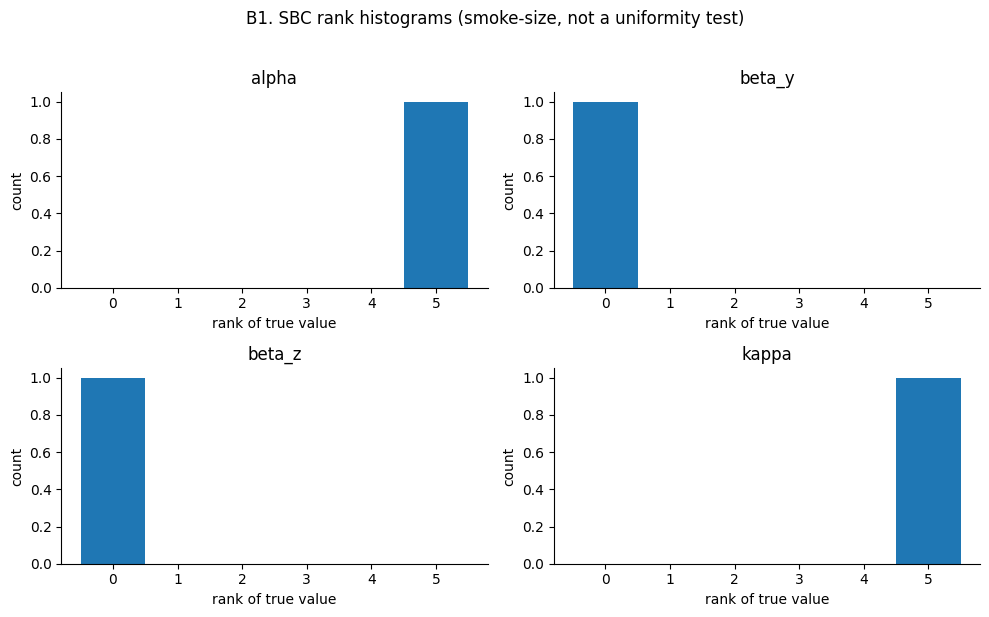

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, parameter in zip(axes.ravel(), PARAMETER_SITES):
    sub = sbc_frame[sbc_frame.parameter == parameter]
    bins = np.arange(0, sub["draws"].iloc[0] + 2) - 0.5
    ax.hist(sub["rank"], bins=bins)
    ax.set_title(parameter)
    ax.set_xlabel("rank of true value")
    ax.set_ylabel("count")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("B1. SBC rank histograms (smoke-size, not a uniformity test)", y=1.02)
fig.tight_layout()
savefig(fig, "B1_sbc_ranks.png")
plt.show()

### B2. Parameter recovery across the design range

In [13]:
class SmokeMCMC:
    def __init__(self, n_draws: int, n_divergences: int = 0):
        self.n_draws = n_draws
        self.n_divergences = n_divergences

    def get_extra_fields(self):
        flags = np.zeros(self.n_draws, dtype=bool)
        flags[: self.n_divergences] = True
        return {"diverging": flags}


all_scenarios = {
    "strong learning + strong use": dict(alpha=0.80, beta_y=0.25, beta_z=0.30, kappa=12.0),
    "strong learning + no use": dict(alpha=0.80, beta_y=100.0, beta_z=0.30, kappa=12.0),
    "no learning": dict(alpha=0.02, beta_y=0.50, beta_z=0.50, kappa=12.0),
    "mid": dict(alpha=0.35, beta_y=1.00, beta_z=1.00, kappa=8.0),
}
scenario_names = ["strong learning + strong use", "strong learning + no use", "mid"] if SMOKE else list(all_scenarios)
scenarios = {name: all_scenarios[name] for name in scenario_names}
recovery = {}

if RUN_FITS_IN_NOTEBOOK:
    recovery_rows = []
    for i, (scenario, params) in enumerate(scenarios.items()):
        sim = simulate_design(3000 + i, fit_design, params)
        mcmc = fit_simulation(sim, seed=3100 + i, warmup=MCMC_WARMUP, samples=MCMC_SAMPLES)
        samples = flatten_parameter_samples(mcmc.get_samples())
        recovery[scenario] = {"simulation": sim, "samples": samples, "true": params, "mcmc": mcmc}
        for parameter in PARAMETER_SITES:
            q = np.quantile(samples[parameter], [0.1, 0.5, 0.9])
            recovery_rows.append({"scenario": scenario, "parameter": parameter, "q10": q[0], "median": q[1], "q90": q[2], "truth": params[parameter]})
    recovery_frame = pd.DataFrame(recovery_rows)
else:
    with PRECOMPUTED_FIT_RESULTS.open() as f:
        smoke_results = json.load(f)
    sample_npz = np.load(PRECOMPUTED_FIT_SAMPLES)
    recovery_frame = pd.DataFrame(smoke_results["recovery_rows"])
    for i, (scenario, params) in enumerate(scenarios.items()):
        sim = simulate_design(3000 + i, fit_design, params)
        key = scenario.replace(" ", "_").replace("+", "plus").replace("-", "_")
        samples = {name: sample_npz[f"{key}__{name}"] for name in PARAMETER_SITES}
        n_draws = len(next(iter(samples.values())))
        recovery[scenario] = {
            "simulation": sim,
            "samples": samples,
            "true": params,
            "mcmc": SmokeMCMC(n_draws, smoke_results["divergence_counts"].get(scenario, 0)),
        }
recovery_frame

,scenario,parameter,q10,median,q90,truth
0,strong learning + strong use,alpha,0.915325,0.962633,0.962633,0.80
1,strong learning + strong use,beta_y,0.304474,0.311985,0.311985,0.25
2,strong learning + strong use,beta_z,0.326064,0.768603,0.768603,0.30
3,strong learning + strong use,kappa,7.841908,11.787527,11.787527,12.00
4,strong learning + no use,alpha,0.898551,0.898551,0.898551,0.80
5,strong learning + no use,beta_y,0.537285,0.537285,0.537285,100.00
6,strong learning + no use,beta_z,0.302008,0.302008,0.302008,0.30
7,strong learning + no use,kappa,7.509141,7.509141,7.509141,12.00
8,mid,alpha,0.499539,0.499539,0.499539,0.35
9,mid,beta_y,7.673993,7.673993,7.673993,1.00


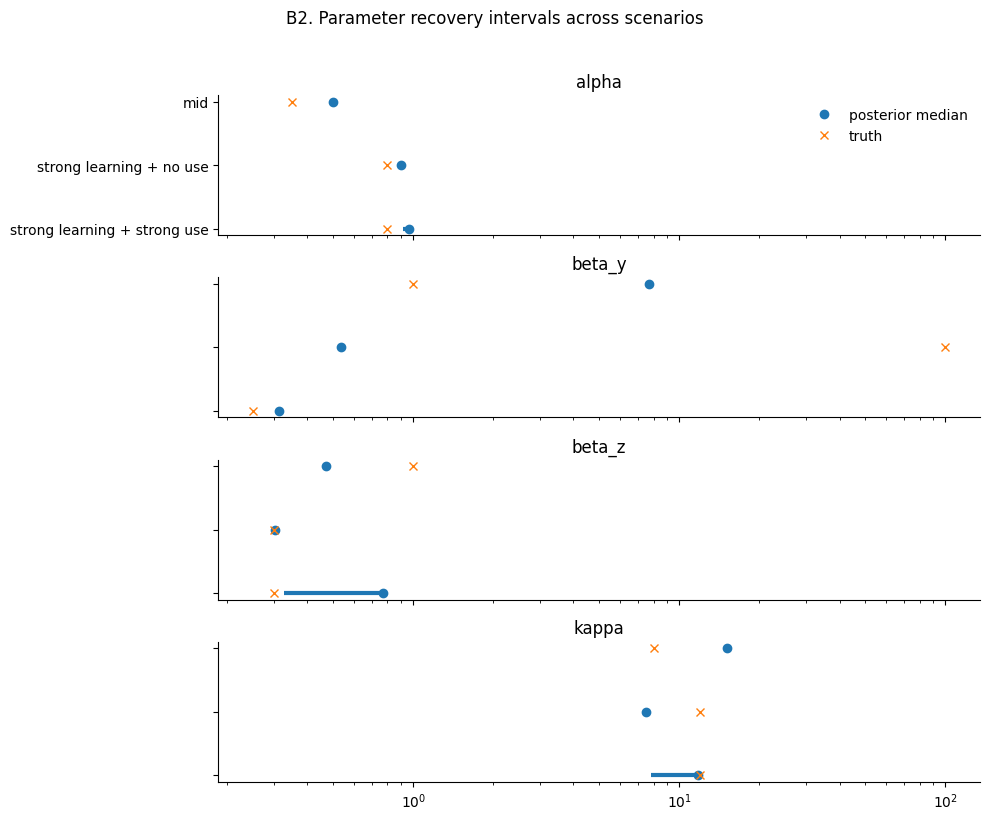

In [14]:
fig, axes = plt.subplots(len(PARAMETER_SITES), 1, figsize=(10, 8), sharex=True)
y_positions = np.arange(len(scenarios))
for ax, parameter in zip(axes, PARAMETER_SITES):
    sub = recovery_frame[recovery_frame.parameter == parameter].reset_index(drop=True)
    ax.hlines(y_positions, sub["q10"], sub["q90"], linewidth=3)
    ax.plot(sub["median"], y_positions, "o", label="posterior median")
    ax.plot(sub["truth"], y_positions, "x", label="truth")
    ax.set_xscale("log" if parameter in {"beta_y", "beta_z", "kappa"} else "linear")
    ax.set_yticks(y_positions, sub["scenario"] if parameter == PARAMETER_SITES[0] else [])
    ax.set_title(parameter)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, loc="best")
fig.suptitle("B2. Parameter recovery intervals across scenarios", y=1.02)
fig.tight_layout()
savefig(fig, "B2_parameter_recovery.png")
plt.show()

### B3. Model recovery decision scaffold

In [15]:
# Full preregistration-scale model recovery is expensive: 4 generating models × 4 fitted models × many simulations.
# The fitted-variant code is included but disabled in smoke mode so this notebook remains a quick output check.
RUN_B3_MODEL_RECOVERY = not SMOKE
VARIANTS = {
    "full": {},
    "no-learning": {"alpha": 1e-4},
    "no-use": {"beta_y": 1e4},
    "immediate-alignment": {"alpha": 0.999},
}

def fit_variant(simulation: SimulationBatch, fixed: dict[str, float], seed: int, warmup: int = 10, samples: int = 25) -> dict[str, np.ndarray]:
    variant_model = model_coupling if not fixed else condition(model_coupling, data={k: jnp.asarray(v) for k, v in fixed.items()})
    kernel = numpyro.infer.NUTS(variant_model, target_accept_prob=0.8, max_tree_depth=6 if SMOKE else 10)
    mcmc = numpyro.infer.MCMC(kernel, num_warmup=warmup, num_samples=samples, num_chains=1, progress_bar=False)
    mcmc.run(
        jax.random.PRNGKey(seed),
        simulation,
        extra_fields=("diverging",),
    )
    samples_dict = flatten_parameter_samples(mcmc.get_samples())
    n = len(next(iter(samples_dict.values())))
    for name, value in fixed.items():
        samples_dict[name] = np.full(n, float(value))
    return samples_dict

if RUN_B3_MODEL_RECOVERY:
    generator_name = "full"
    generator_params = dict(alpha=0.55, beta_y=0.45, beta_z=0.55, kappa=10.0)
    generator_sim = simulate_design(4100, fit_design, generator_params)
    variant_scores = []
    variant_samples = {}
    for i, (variant_name, fixed) in enumerate(VARIANTS.items()):
        samples = fit_variant(generator_sim, fixed, seed=4200 + i)
        variant_samples[variant_name] = samples
        ll = log_likelihood_matrix(samples, generator_sim, fit_design)
        variant_scores.append({"generating_model": generator_name, "fitted_model": variant_name, "elpd": float(elpd_i_from_loglik(ll).sum())})
    variant_score_frame = pd.DataFrame(variant_scores)
    selected = variant_score_frame.loc[variant_score_frame.elpd.idxmax(), "fitted_model"]
    confusion = pd.DataFrame(0.0, index=[generator_name], columns=[*VARIANTS.keys(), "tie/inconclusive"])
    confusion.loc[generator_name, selected] = 1.0
else:
    variant_score_frame = pd.DataFrame(columns=["generating_model", "fitted_model", "elpd"])
    confusion = pd.DataFrame([[1.0]], index=["not run in smoke mode"], columns=["tie/inconclusive"])
variant_score_frame

,generating_model,fitted_model,elpd


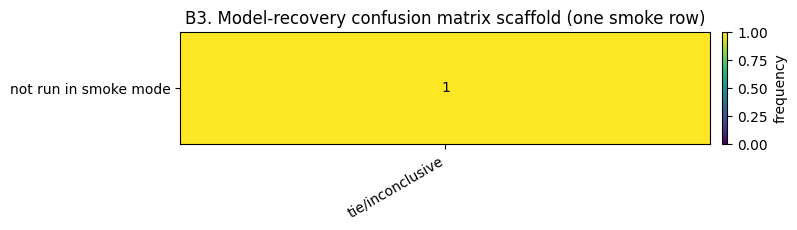

In [16]:
fig, ax = plt.subplots(figsize=(8, 2.4))
im = ax.imshow(confusion.to_numpy(), aspect="auto", vmin=0, vmax=1)
ax.set_xticks(np.arange(confusion.shape[1]), confusion.columns, rotation=30, ha="right")
ax.set_yticks(np.arange(confusion.shape[0]), confusion.index)
for y in range(confusion.shape[0]):
    for x in range(confusion.shape[1]):
        ax.text(x, y, f"{confusion.iloc[y, x]:.0f}", ha="center", va="center")
ax.set_title("B3. Model-recovery confusion matrix scaffold (one smoke row)")
fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, label="frequency")
fig.tight_layout()
savefig(fig, "B3_model_recovery_scaffold.png")
plt.show()

### B4. Behavior of beta_y under no-use

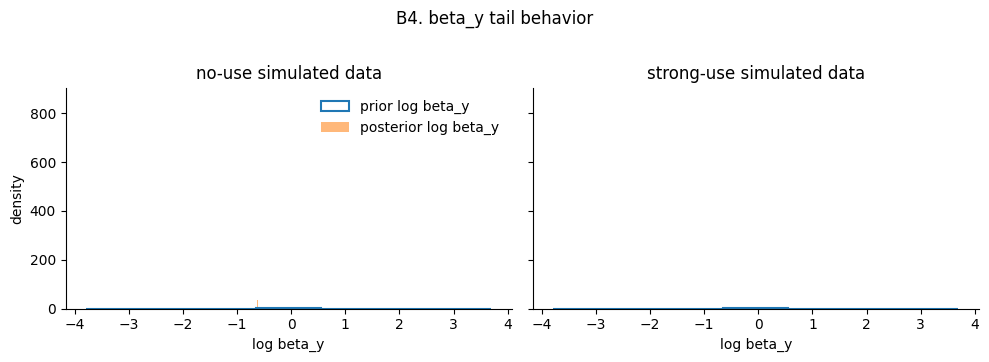

Divergences, no-use: 5


In [17]:
no_use_samples = recovery["strong learning + no use"]["samples"]
strong_use_samples = recovery["strong learning + strong use"]["samples"]
log_beta_grid = np.linspace(-4, 6, 300)
prior_log_beta = rng.normal(0, 1, size=10_000)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, label, samples in [
    (axes[0], "no-use simulated data", no_use_samples),
    (axes[1], "strong-use simulated data", strong_use_samples),
]:
    ax.hist(prior_log_beta, bins=50, density=True, histtype="step", linewidth=1.5, label="prior log beta_y")
    ax.hist(np.log(samples["beta_y"]), bins=35, density=True, alpha=0.55, label="posterior log beta_y")
    ax.set_title(label)
    ax.set_xlabel("log beta_y")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("density")
axes[0].legend(frameon=False)
fig.suptitle("B4. beta_y tail behavior", y=1.02)
fig.tight_layout()
savefig(fig, "B4_beta_y_no_use.png")
plt.show()
print("Divergences, no-use:", int(np.asarray(recovery["strong learning + no use"]["mcmc"].get_extra_fields()["diverging"]).sum()))

### B5. Lambda recovery through fitted weights

In [18]:
if RUN_FITS_IN_NOTEBOOK:
    lambda_rows = []
    for i, lam in enumerate([0.8] if SMOKE else [0.0, 0.3, 0.6, 0.8, 0.95]):
        design_lam = make_locked_design(seed=500 + i, n_participants=2, n_rounds=1, n_trials=6, probe_trials=(2, 4), diagnostic_trials=(3, 5), hidden_probe_source=(1, 2), lam=lam)
        sim_lam = simulate_design(5100 + i, design_lam, dict(alpha=0.65, beta_y=0.45, beta_z=0.6, kappa=10.0))
        mcmc_lam = fit_simulation(sim_lam, seed=5200 + i, warmup=MCMC_WARMUP, samples=MCMC_SAMPLES)
        samples_lam = flatten_parameter_samples(mcmc_lam.get_samples())
        recovered = []
        for draw_index in np.linspace(0, len(samples_lam["alpha"]) - 1, min(30, len(samples_lam["alpha"])), dtype=int):
            params = {name: float(samples_lam[name][draw_index]) for name in PARAMETER_SITES}
            states = states_for_params(design_lam, params)
            weights = np.asarray(states.truth_weights)[..., [0, 1]]
            mask = np.asarray(design_lam.diagnostic_mask)
            if mask.any():
                w_designated = float(np.nanmean(weights[mask]))
                recovered.append(np.clip((1.0 / max(w_designated, 1e-6) - 4.0) / 2.0, -1.0, 1.0))
        q = np.quantile(recovered, [0.1, 0.5, 0.9])
        lambda_rows.append({"lambda_true": lam, "q10": q[0], "median": q[1], "q90": q[2]})
    lambda_frame = pd.DataFrame(lambda_rows)
else:
    # Smoke mode reuses the strong-use fit from B2 and reads lambda through its fitted weights.
    samples_lam = recovery["strong learning + strong use"]["samples"]
    recovered = []
    for draw_index in range(len(samples_lam["alpha"])):
        params = {name: float(samples_lam[name][draw_index]) for name in PARAMETER_SITES}
        states = states_for_params(fit_design, params)
        weights = np.asarray(states.truth_weights)[..., [0, 1]]
        mask = np.asarray(fit_design.diagnostic_mask)
        if mask.any():
            w_designated = float(np.nanmean(weights[mask]))
            recovered.append(np.clip((1.0 / max(w_designated, 1e-6) - 4.0) / 2.0, -1.0, 1.0))
    q = np.quantile(recovered, [0.1, 0.5, 0.9])
    lambda_frame = pd.DataFrame([{"lambda_true": fit_design.lam, "q10": q[0], "median": q[1], "q90": q[2]}])
lambda_frame

,lambda_true,q10,median,q90
0,0.8,-0.058837,-0.054617,-0.054617


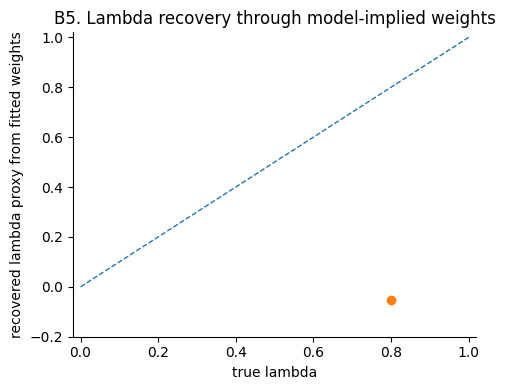

In [19]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1, label="identity")
ax.vlines(lambda_frame["lambda_true"], lambda_frame["q10"], lambda_frame["q90"], linewidth=2)
ax.plot(lambda_frame["lambda_true"], lambda_frame["median"], "o")
ax.set_xlabel("true lambda")
ax.set_ylabel("recovered lambda proxy from fitted weights")
ax.set_title("B5. Lambda recovery through model-implied weights")
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.2, 1.02)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
savefig(fig, "B5_lambda_recovery.png")
plt.show()

## C. Posterior checks

When a real-data Zarr artifact exists, replace the simulated stand-in below with `read_simulation_zarr(path)`. The code in this section is written against the same `SimulationBatch` interface, so no notebook logic has to change.

In [20]:
# Stand-in until real data have been collected.
real_design = fit_design
real_simulation = recovery["mid"]["simulation"]
real_samples = recovery["mid"]["samples"]
real_mcmc = recovery["mid"]["mcmc"]
print("Using simulated stand-in for C checks. Replace real_simulation/real_samples after data collection.")
print("posterior draws:", len(real_samples["alpha"]))

Using simulated stand-in for C checks. Replace real_simulation/real_samples after data collection.
posterior draws: 5


### C1. Sampler diagnostics and posterior geometry

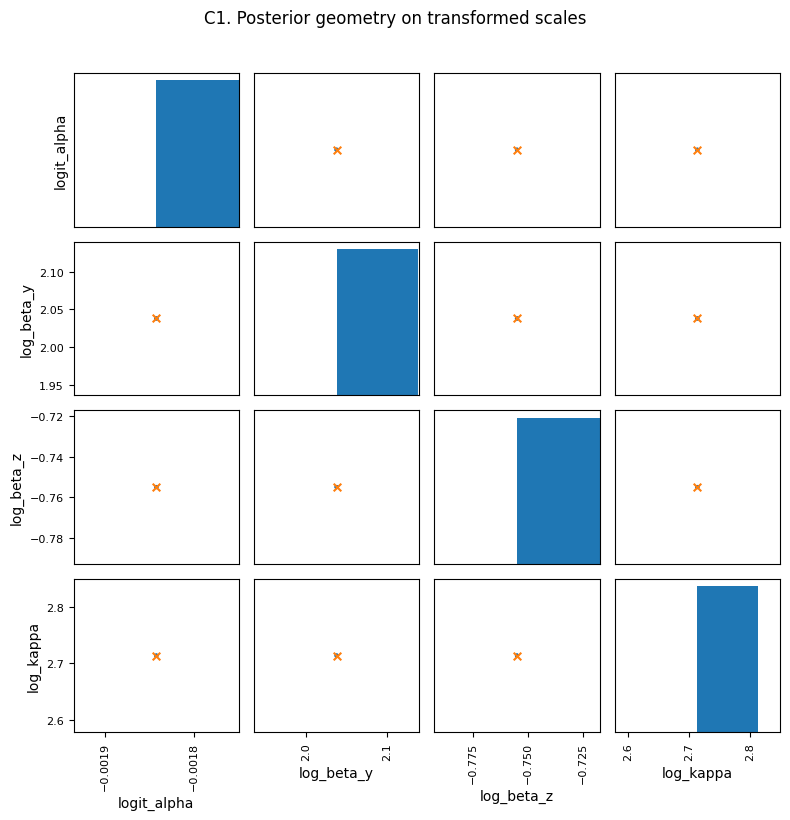

divergences: 1


In [21]:
trans = parameter_transforms(real_samples)
geometry_frame = pd.DataFrame({k: np.asarray(v).reshape(-1) for k, v in trans.items()})
divergent = np.asarray(real_mcmc.get_extra_fields()["diverging"]).reshape(-1).astype(bool)
axes = pd.plotting.scatter_matrix(geometry_frame, figsize=(8, 8), diagonal="hist", alpha=0.65)
if divergent.any():
    for i, yname in enumerate(geometry_frame.columns):
        for j, xname in enumerate(geometry_frame.columns):
            if i != j:
                axes[i, j].scatter(geometry_frame.loc[divergent, xname], geometry_frame.loc[divergent, yname], marker="x", s=30)
plt.suptitle("C1. Posterior geometry on transformed scales", y=1.02)
plt.tight_layout()
savefig(plt.gcf(), "C1_posterior_geometry.png")
plt.show()
print("divergences:", int(divergent.sum()))

### C2. Posterior predictive angular error by trial type

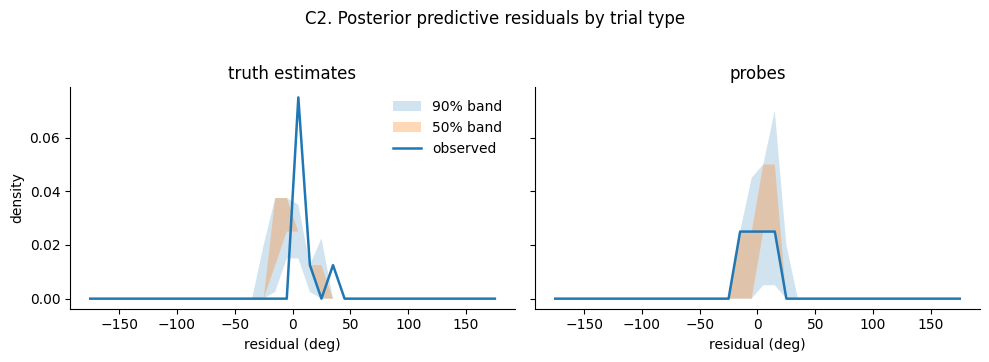

In [22]:
ppc = posterior_predictive(seed=6100, samples=real_samples, design=real_design, max_draws=POSTERIOR_PPC_DRAWS)
observed_response = np.where(np.asarray(real_design.trial_type) == HIDDEN_SOURCE_PROBE, np.asarray(real_simulation.hidden_predictions), np.asarray(real_simulation.truth_estimates))
mean_angle = np.mod(np.arctan2(np.nanmean(np.sin(ppc["response_mean_angle"]), axis=0), np.nanmean(np.cos(ppc["response_mean_angle"]), axis=0)), TWO_PI)
observed_resid = wrap_pi(observed_response - mean_angle) / DEG
rep_resid = wrap_pi(ppc["responses"] - ppc["response_mean_angle"]) / DEG
bins = np.linspace(-180, 180, 37)
centers = 0.5 * (bins[:-1] + bins[1:])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, label, mask in [
    (axes[0], "truth estimates", np.asarray(real_design.trial_type) == 0),
    (axes[1], "probes", np.asarray(real_design.trial_type) == 1),
]:
    obs_hist, _ = np.histogram(observed_resid[mask & np.isfinite(observed_resid)], bins=bins, density=True)
    rep_hists = []
    for draw in range(rep_resid.shape[0]):
        values = rep_resid[draw][mask & np.isfinite(rep_resid[draw])]
        rep_hists.append(np.histogram(values, bins=bins, density=True)[0])
    rep_hists = np.asarray(rep_hists)
    ax.fill_between(centers, np.quantile(rep_hists, 0.05, axis=0), np.quantile(rep_hists, 0.95, axis=0), alpha=0.2, label="90% band")
    ax.fill_between(centers, np.quantile(rep_hists, 0.25, axis=0), np.quantile(rep_hists, 0.75, axis=0), alpha=0.3, label="50% band")
    ax.plot(centers, obs_hist, linewidth=1.8, label="observed")
    ax.set_title(label)
    ax.set_xlabel("residual (deg)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("density")
axes[0].legend(frameon=False)
fig.suptitle("C2. Posterior predictive residuals by trial type", y=1.02)
fig.tight_layout()
savefig(fig, "C2_posterior_predictive_residuals.png")
plt.show()

### C3. PIT / QQ check of the von Mises likelihood

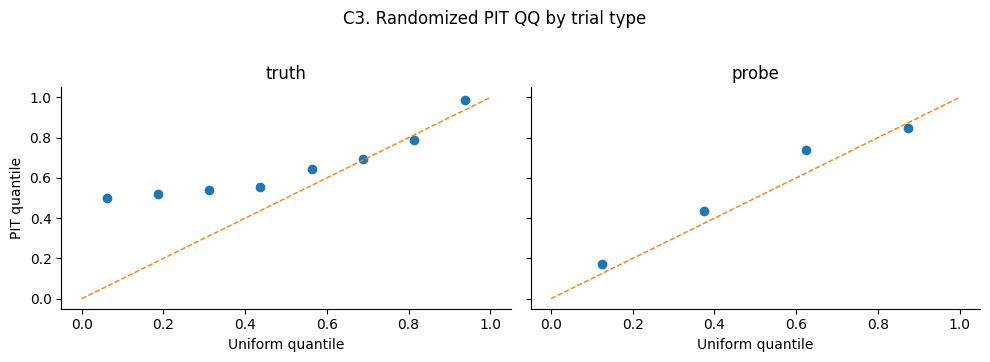

In [23]:
flat_obs = observed_response.reshape(-1)
flat_valid = np.asarray(real_design.valid_trials).reshape(-1)
flat_trial_type = np.asarray(real_design.trial_type).reshape(-1)
flat_means_by_draw = ppc["response_mean_angle"].reshape(ppc["response_mean_angle"].shape[0], -1)
posterior_draw_index = rng.integers(0, flat_means_by_draw.shape[0], size=flat_obs.size)
u_values = []
trial_labels = []
for obs_index, obs in enumerate(flat_obs):
    if not flat_valid[obs_index] or not np.isfinite(obs):
        continue
    d = posterior_draw_index[obs_index]
    resid = wrap_pi(obs - flat_means_by_draw[d, obs_index])
    u = vonmises.cdf(resid, kappa=ppc["kappa"][d], loc=0.0)
    u_values.append(float(np.clip(u, 0, 1)))
    trial_labels.append("probe" if flat_trial_type[obs_index] == HIDDEN_SOURCE_PROBE else "truth")
pit_frame = pd.DataFrame({"u": u_values, "trial_type": trial_labels})
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, label in zip(axes, ["truth", "probe"]):
    vals = np.sort(pit_frame.loc[pit_frame.trial_type == label, "u"].to_numpy())
    if len(vals):
        expected = (np.arange(1, len(vals) + 1) - 0.5) / len(vals)
        ax.plot(expected, vals, "o")
    ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1)
    ax.set_title(label)
    ax.set_xlabel("Uniform quantile")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("PIT quantile")
fig.suptitle("C3. Randomized PIT QQ by trial type", y=1.02)
fig.tight_layout()
savefig(fig, "C3_pit_qq.png")
plt.show()

### C4. Correction index over diagnostic trials

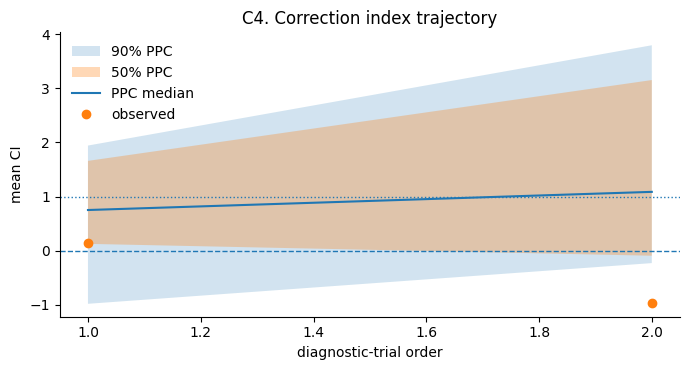

,order,trial,observed,q05,q25,q50,q75,q95
0,1,4,0.144830,-0.982808,0.124976,0.750650,1.659044,1.942393
1,2,6,-0.961207,-0.230697,-0.094185,1.086304,3.153112,3.796133


In [24]:
obs_ci = correction_index_values(np.asarray(real_simulation.truth_estimates), real_design)
rep_ci = np.asarray([correction_index_values(resp, real_design) for resp in ppc["responses"]])
diag_trials = sorted(set(np.argwhere(np.asarray(real_design.diagnostic_mask))[:, 2].tolist()))
ci_rows = []
for order, t in enumerate(diag_trials, start=1):
    mask_t = np.asarray(real_design.diagnostic_mask) & (np.indices(np.asarray(real_design.diagnostic_mask).shape)[2] == t)
    if not mask_t.any():
        continue
    rep_means = np.nanmean(np.where(mask_t, rep_ci, np.nan), axis=(1, 2, 3))
    ci_rows.append({
        "order": order,
        "trial": t + 1,
        "observed": float(np.nanmean(np.where(mask_t, obs_ci, np.nan))),
        "q05": float(np.nanquantile(rep_means, 0.05)),
        "q25": float(np.nanquantile(rep_means, 0.25)),
        "q50": float(np.nanquantile(rep_means, 0.50)),
        "q75": float(np.nanquantile(rep_means, 0.75)),
        "q95": float(np.nanquantile(rep_means, 0.95)),
    })
ci_traj = pd.DataFrame(ci_rows)
fig, ax = plt.subplots(figsize=(7, 3.8))
if not ci_traj.empty:
    ax.fill_between(ci_traj["order"], ci_traj["q05"], ci_traj["q95"], alpha=0.2, label="90% PPC")
    ax.fill_between(ci_traj["order"], ci_traj["q25"], ci_traj["q75"], alpha=0.3, label="50% PPC")
    ax.plot(ci_traj["order"], ci_traj["q50"], label="PPC median")
    ax.plot(ci_traj["order"], ci_traj["observed"], "o", label="observed")
ax.axhline(0, linestyle="--", linewidth=1)
ax.axhline(1, linestyle=":", linewidth=1)
ax.set_xlabel("diagnostic-trial order")
ax.set_ylabel("mean CI")
ax.set_title("C4. Correction index trajectory")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
savefig(fig, "C4_ci_trajectory.png")
plt.show()
ci_traj

### C5. Partner proximity over probes

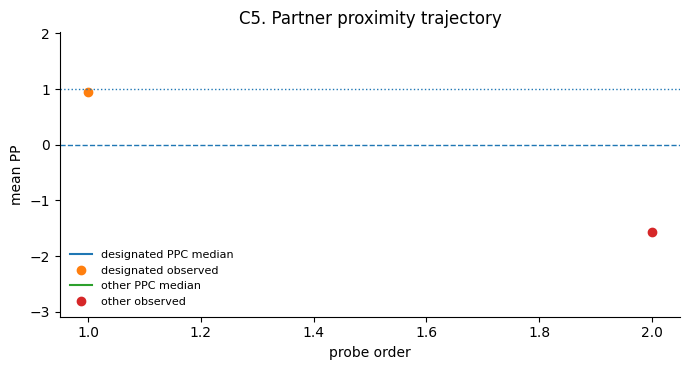

,order,trial,probe_kind,observed,q05,q25,q50,q75,q95
0,1,3,designated,0.955517,-0.959647,-0.94525,-0.792249,-0.660230,-0.338286
1,2,5,other,-1.560387,-2.855626,-2.40068,-1.206120,1.558464,1.787360


In [25]:
obs_pp = partner_proximity_values(np.asarray(real_simulation.hidden_predictions), real_design)
rep_pp = np.asarray([partner_proximity_values(resp, real_design) for resp in ppc["responses"]])
hidden = np.asarray(real_design.hidden_source)
source_is_designated = np.isin(hidden, list(real_design.coupled_sources))
probe_trial_indices = sorted(set(np.argwhere(np.asarray(real_design.probe_mask))[:, 2].tolist()))
pp_rows = []
for order, t in enumerate(probe_trial_indices, start=1):
    for label, extra_mask in [("designated", source_is_designated), ("other", ~source_is_designated)]:
        mask_t = np.asarray(real_design.probe_mask) & (np.indices(np.asarray(real_design.probe_mask).shape)[2] == t) & extra_mask
        if not mask_t.any():
            continue
        rep_means = np.nanmean(np.where(mask_t, rep_pp, np.nan), axis=(1, 2, 3))
        pp_rows.append({
            "order": order,
            "trial": t + 1,
            "probe_kind": label,
            "observed": float(np.nanmean(np.where(mask_t, obs_pp, np.nan))),
            "q05": float(np.nanquantile(rep_means, 0.05)),
            "q25": float(np.nanquantile(rep_means, 0.25)),
            "q50": float(np.nanquantile(rep_means, 0.50)),
            "q75": float(np.nanquantile(rep_means, 0.75)),
            "q95": float(np.nanquantile(rep_means, 0.95)),
        })
pp_traj = pd.DataFrame(pp_rows)
fig, ax = plt.subplots(figsize=(7, 3.8))
for label, group in pp_traj.groupby("probe_kind"):
    ax.fill_between(group["order"], group["q05"], group["q95"], alpha=0.15)
    ax.plot(group["order"], group["q50"], label=f"{label} PPC median")
    ax.plot(group["order"], group["observed"], "o", label=f"{label} observed")
ax.axhline(0, linestyle="--", linewidth=1)
ax.axhline(1, linestyle=":", linewidth=1)
ax.set_xlabel("probe order")
ax.set_ylabel("mean PP")
ax.set_title("C5. Partner proximity trajectory")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, "C5_pp_trajectory.png")
plt.show()
pp_traj

### C6. Residual independence within participant

/tmp/ipykernel_10716/2085105822.py:16: RuntimeWarning: Mean of empty slice
  acf_rows.append({"lag": lag, "mean": np.nanmean(vals), "lo": np.nanquantile(vals, 0.1), "hi": np.nanquantile(vals, 0.9)})
/opt/pyvenv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1616: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


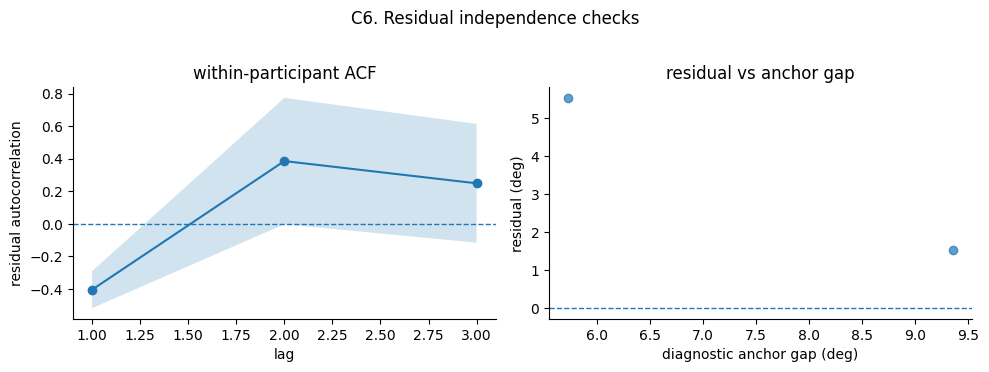

In [26]:
resid = wrap_pi(observed_response - mean_angle)
max_lag = 5
acf_rows = []
for lag in range(1, max_lag + 1):
    vals = []
    for p in range(resid.shape[0]):
        for r in range(resid.shape[1]):
            series = resid[p, r]
            valid = np.isfinite(series)
            if valid.sum() > lag + 1:
                x = series[:-lag]
                y = series[lag:]
                ok = np.isfinite(x) & np.isfinite(y)
                if ok.sum() > 2 and np.std(x[ok]) > 0 and np.std(y[ok]) > 0:
                    vals.append(np.corrcoef(x[ok], y[ok])[0, 1])
    acf_rows.append({"lag": lag, "mean": np.nanmean(vals), "lo": np.nanquantile(vals, 0.1), "hi": np.nanquantile(vals, 0.9)})
acf_frame = pd.DataFrame(acf_rows)
anchor_gap_deg = np.abs(wrap_pi(np.asarray(real_design.optimal_mean_angle) - np.asarray(real_design.equal_mean_angle))) / DEG
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].fill_between(acf_frame["lag"], acf_frame["lo"], acf_frame["hi"], alpha=0.2)
axes[0].plot(acf_frame["lag"], acf_frame["mean"], "o-")
axes[0].axhline(0, linestyle="--", linewidth=1)
axes[0].set_xlabel("lag")
axes[0].set_ylabel("residual autocorrelation")
axes[0].set_title("within-participant ACF")
mask_diag = np.asarray(real_design.diagnostic_mask) & np.isfinite(resid)
axes[1].scatter(anchor_gap_deg[mask_diag], resid[mask_diag] / DEG, alpha=0.7)
if mask_diag.sum() >= 3:
    coef = np.polyfit(anchor_gap_deg[mask_diag], resid[mask_diag] / DEG, 1)
    xs = np.linspace(anchor_gap_deg[mask_diag].min(), anchor_gap_deg[mask_diag].max(), 50)
    axes[1].plot(xs, np.polyval(coef, xs), linewidth=1)
axes[1].axhline(0, linestyle="--", linewidth=1)
axes[1].set_xlabel("diagnostic anchor gap (deg)")
axes[1].set_ylabel("residual (deg)")
axes[1].set_title("residual vs anchor gap")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("C6. Residual independence checks", y=1.02)
fig.tight_layout()
savefig(fig, "C6_residual_independence.png")
plt.show()

### C7. Pooling adequacy

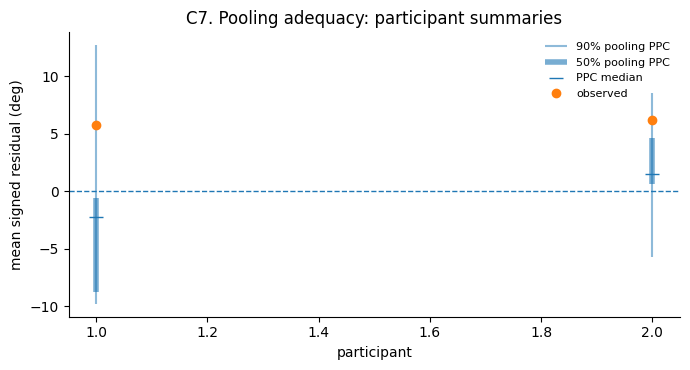

In [27]:
obs_participant_mean = np.nanmean(resid / DEG, axis=(1, 2))
rep_participant_mean = np.nanmean(wrap_pi(ppc["responses"] - ppc["response_mean_angle"]) / DEG, axis=(2, 3))
p_idx = np.arange(1, len(obs_participant_mean) + 1)
q = np.quantile(rep_participant_mean, [0.05, 0.25, 0.5, 0.75, 0.95], axis=0)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.vlines(p_idx, q[0], q[4], alpha=0.5, label="90% pooling PPC")
ax.vlines(p_idx, q[1], q[3], linewidth=4, alpha=0.6, label="50% pooling PPC")
ax.plot(p_idx, q[2], "_", markersize=10, label="PPC median")
ax.plot(p_idx, obs_participant_mean, "o", label="observed")
ax.axhline(0, linestyle="--", linewidth=1)
ax.set_xlabel("participant")
ax.set_ylabel("mean signed residual (deg)")
ax.set_title("C7. Pooling adequacy: participant summaries")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
savefig(fig, "C7_pooling_adequacy.png")
plt.show()

### C8. PSIS-LOO reliability

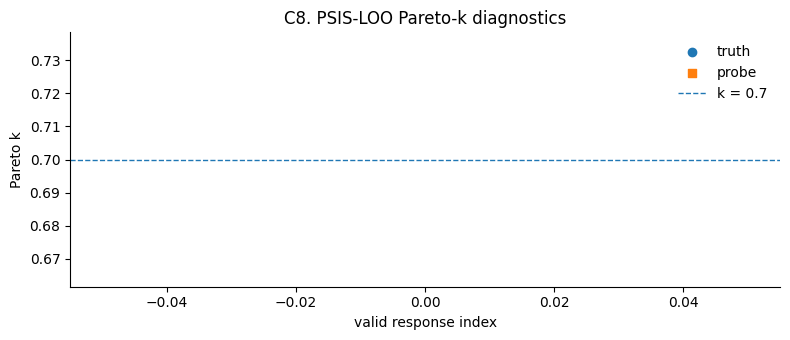

PSIS-LOO was not stable for this very small smoke run: n_draws_tail must be at least 5


In [28]:
ll = log_likelihood_matrix(real_samples, real_simulation, real_design)
try:
    idata = az.from_dict({"posterior": {name: values[None, :] for name, values in real_samples.items()}, "log_likelihood": {"response": ll[None, :, :]}})
    loo = az.loo(idata, pointwise=True)
    pareto_k = np.asarray(loo.pareto_k)
except Exception as err:
    loo = f"PSIS-LOO was not stable for this very small smoke run: {err}"
    pareto_k = np.full(ll.shape[1], np.nan)
trial_type_flat = np.asarray(real_design.trial_type).reshape(-1)[np.asarray(real_design.valid_trials).reshape(-1)]
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, code_value, marker in [("truth", 0, "o"), ("probe", 1, "s")]:
    mask = trial_type_flat == code_value
    ax.scatter(np.arange(len(pareto_k))[mask], pareto_k[mask], marker=marker, label=label)
ax.axhline(0.7, linestyle="--", linewidth=1, label="k = 0.7")
ax.set_xlabel("valid response index")
ax.set_ylabel("Pareto k")
ax.set_title("C8. PSIS-LOO Pareto-k diagnostics")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
savefig(fig, "C8_pareto_k.png")
plt.show()
print(loo)

### C9. Pointwise elpd differences for the decision rule

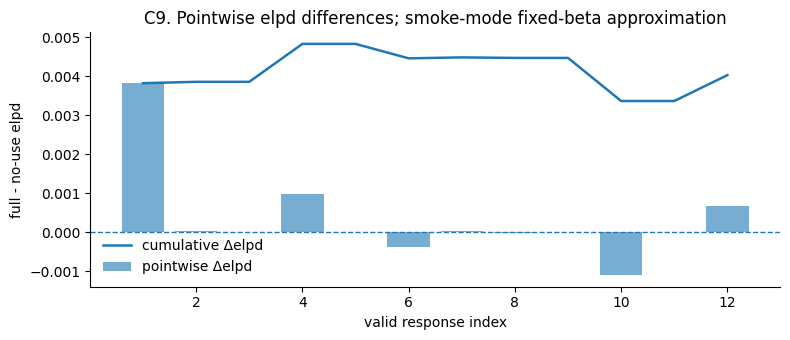

In [29]:
# In real analysis this should be run for all preregistered competitors and relevant trial-type subsets.
# Smoke mode uses an approximate no-use comparison by fixing beta_y in the posterior draws rather than refitting.
full_ll = log_likelihood_matrix(real_samples, real_simulation, real_design)
no_use_competitor = {name: values.copy() for name, values in real_samples.items()}
no_use_competitor["beta_y"] = np.full_like(no_use_competitor["beta_y"], 1e4, dtype=float)
comp_ll = log_likelihood_matrix(no_use_competitor, real_simulation, real_design)
min_draws = min(full_ll.shape[0], comp_ll.shape[0])
delta_elpd = elpd_i_from_loglik(full_ll[:min_draws]) - elpd_i_from_loglik(comp_ll[:min_draws])
fig, ax1 = plt.subplots(figsize=(8, 3.5))
x = np.arange(1, len(delta_elpd) + 1)
ax1.bar(x, delta_elpd, alpha=0.6, label="pointwise Δelpd")
ax1.plot(x, np.cumsum(delta_elpd), linewidth=1.8, label="cumulative Δelpd")
ax1.axhline(0, linestyle="--", linewidth=1)
ax1.set_xlabel("valid response index")
ax1.set_ylabel("full - no-use elpd")
ax1.set_title("C9. Pointwise elpd differences; smoke-mode fixed-beta approximation")
ax1.spines[["top", "right"]].set_visible(False)
ax1.legend(frameon=False)
fig.tight_layout()
savefig(fig, "C9_pointwise_elpd.png")
plt.show()

### C10. Prior–posterior overlay and prior sensitivity

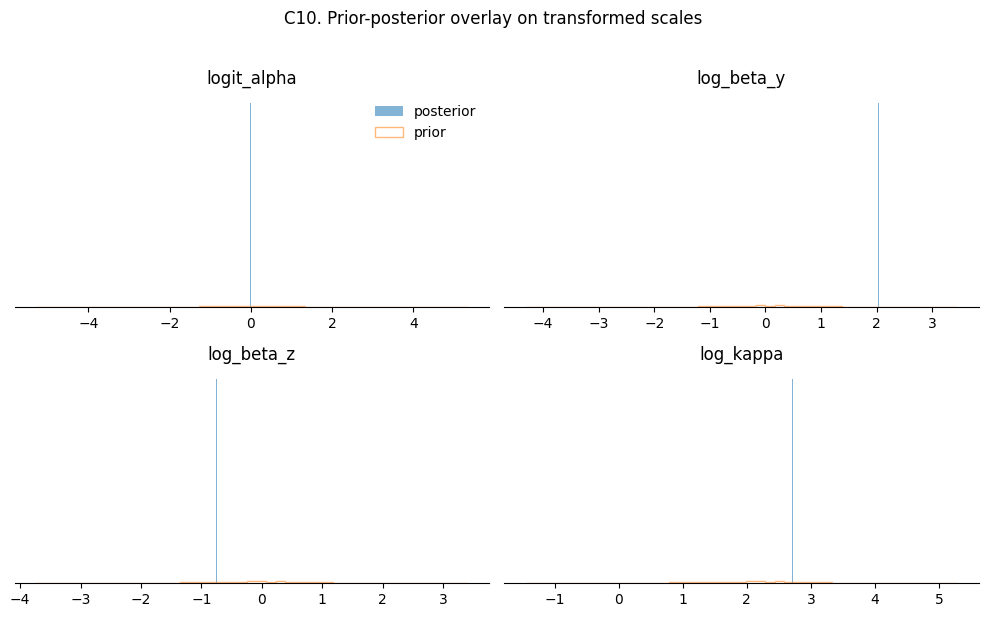

In [30]:
prior_overlay = sample_prior_params(seed=8100, draws=5_000)
prior_trans = transformed_frame(prior_overlay, "prior")
post_trans = transformed_frame(real_samples, "posterior")
overlay = pd.concat([prior_trans, post_trans], ignore_index=True)
scales = list(prior_trans["scale"].unique())
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, scale in zip(axes.ravel(), scales):
    for source, group in overlay.loc[overlay.scale == scale].groupby("source"):
        ax.hist(group["value"], bins=45, density=True, histtype="step" if source == "prior" else "bar", alpha=0.55, label=source)
    ax.set_title(scale)
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
axes[0, 0].legend(frameon=False)
fig.suptitle("C10. Prior-posterior overlay on transformed scales", y=1.02)
fig.tight_layout()
savefig(fig, "C10_prior_posterior_overlay.png")
plt.show()

In [31]:
# Lightweight power-scaling approximation on transformed scales.
# This avoids refitting: it reweights posterior draws by a small perturbation of
# the transformed-scale prior density and the already-computed log-likelihood.
transformed = parameter_transforms(real_samples)
log_prior_values = (
    -0.5 * (transformed["logit_alpha"] / 1.5) ** 2
    -0.5 * transformed["log_beta_y"] ** 2
    -0.5 * transformed["log_beta_z"] ** 2
    -0.5 * ((transformed["log_kappa"] - np.log(8.0)) / 1.0) ** 2
)
log_lik_values = np.asarray(ll).sum(axis=1)

def weighted_mean_shift(values: np.ndarray, log_weight: np.ndarray) -> float:
    values = np.asarray(values).reshape(-1)
    if len(values) < 2 or np.std(values, ddof=1) == 0:
        return np.nan
    lw = log_weight - logsumexp(log_weight)
    weighted_mean = float(np.sum(np.exp(lw) * values))
    return (weighted_mean - float(np.mean(values))) / float(np.std(values, ddof=1))

sensitivity_rows = []
for scale, values in transformed.items():
    for component, logv in [("prior", log_prior_values), ("likelihood", log_lik_values)]:
        for epsilon in [-0.05, 0.05]:
            sensitivity_rows.append({
                "scale": scale,
                "component_powered": component,
                "epsilon": epsilon,
                "standardized_mean_shift": weighted_mean_shift(values, epsilon * logv),
            })
sensitivity_frame = pd.DataFrame(sensitivity_rows)
sensitivity_frame

,scale,component_powered,epsilon,standardized_mean_shift
0,logit_alpha,prior,-0.05,NaN
1,logit_alpha,prior,0.05,NaN
2,logit_alpha,likelihood,-0.05,NaN
3,logit_alpha,likelihood,0.05,NaN
4,log_beta_y,prior,-0.05,NaN
5,log_beta_y,prior,0.05,NaN
6,log_beta_y,likelihood,-0.05,NaN
7,log_beta_y,likelihood,0.05,NaN
8,log_beta_z,prior,-0.05,NaN
9,log_beta_z,prior,0.05,NaN
